# Лабораторная работа №3

Полный запуск этапов выполняется последовательно из этого Notebook.

In [1]:
from pathlib import Path
import json
import re
import subprocess
import sys
import time
import pandas as pd
import requests

sys.dont_write_bytecode = True
ROOT = Path.cwd()
if ROOT.name != 'lab_3':
    ROOT = next(path for path in [ROOT, *ROOT.parents] if path.name == 'lab_3')
sys.path.insert(0, str(ROOT))
print(ROOT)

C:\Users\alexm\Desktop\Рабочая папка\ITiABD\Курс 4\РсОД\lab_3


In [2]:
# Локальный учебный каталог и сервер
from make_catalog import build_catalog
build_catalog(ROOT / 'organizations.csv', ROOT / 'site')
server = subprocess.Popen(
    [sys.executable, str(ROOT / 'delay_server.py'), '--dir', str(ROOT / 'site'), '--port', '8765', '--delay', '0.12'],
    cwd=ROOT,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)
for _ in range(30):
    try:
        response = requests.get('http://127.0.0.1:8765/index.html', timeout=1)
        response.raise_for_status()
        print('server ready:', response.status_code)
        break
    except requests.RequestException:
        time.sleep(0.2)
else:
    server.terminate()
    raise RuntimeError('Local server did not start')

server ready: 200


In [3]:
# Два независимых скрапера
subprocess.run(
    [sys.executable, str(ROOT / 'src' / 'bs_scraper.py'), '--start-url', 'http://127.0.0.1:8765/index.html'],
    cwd=ROOT, check=True,
)
subprocess.run(
    ['scrapy', 'runspider', str(ROOT / 'src' / 'catalog_spider.py'), '-a', 'start_url=http://127.0.0.1:8765/index.html', '-O', str(ROOT / 'data/raw/catalog_scrapy.jsonl')],
    cwd=ROOT, check=True,
)
bs_rows = pd.read_csv(ROOT / 'data/raw/catalog_bs.csv')
scrapy_rows = [json.loads(line) for line in (ROOT / 'data/raw/catalog_scrapy.jsonl').read_text(encoding='utf-8').splitlines() if line]
print(len(bs_rows), len(scrapy_rows))

10 10


In [4]:
# Очистка и автоматические проверки
clean = bs_rows.copy()
clean['org_id'] = pd.to_numeric(clean['org_id'], errors='raise').astype('int64')
clean['reports_count'] = pd.to_numeric(clean['reports_count'], errors='coerce').astype('Int64')
clean = clean.drop_duplicates('org_id', keep='first')
scrapy_by_id = {str(row['org_id']): row for row in scrapy_rows}
assert clean['org_id'].is_unique
assert clean['reports_count'].dropna().ge(0).all()
assert clean['last_reviewed'].dropna().map(lambda x: bool(re.fullmatch(r'\d{4}-\d{2}-\d{2}', x))).all()
assert set(clean['org_id'].astype(str)) == set(scrapy_by_id)
for _, row in clean.iterrows():
    other = scrapy_by_id[str(row['org_id'])]
    for field in ('org_name', 'sector', 'last_reviewed', 'description', 'reports_count'):
        assert str(row[field]) == str(other[field])
clean.to_csv(ROOT / 'data/processed/catalog_clean.csv', index=False)
quality = pd.DataFrame([
    ['unique_org_id', f'{clean.org_id.nunique()} of {len(clean)}', 'passed'],
    ['reports_count_non_negative', '0 negative values', 'passed'],
    ['iso_dates', '0 invalid dates', 'passed'],
    ['scraper_keys_and_fields_match', f'{len(clean)} common org_id', 'passed'],
], columns=['check_name', 'actual_result', 'status'])
quality.to_csv(ROOT / 'results/quality_report.csv', index=False)
quality

,check_name,actual_result,status
0,unique_org_id,10 of 10,passed
1,reports_count_non_negative,0 negative values,passed
2,iso_dates,0 invalid dates,passed
3,scraper_keys_and_fields_match,10 common org_id,passed


In [5]:
# I/O и CPU benchmark запускаются отдельными процессами; это безопасно для Windows
subprocess.run([sys.executable, str(ROOT / 'src/benchmark_io.py'), '--base-url', 'http://127.0.0.1:8765/', '--repeat', '2', '--runs', '3'], cwd=ROOT, check=True)
subprocess.run([sys.executable, str(ROOT / 'src/benchmark_cpu.py'), '--input', str(ROOT / 'data/processed/catalog_clean.csv'), '--fragments', '200', '--runs', '3'], cwd=ROOT, check=True)
io_results = pd.read_csv(ROOT / 'results/benchmark.csv')
(ROOT / 'results/benchmark_summary.csv').unlink(missing_ok=True)
cpu_results = pd.read_csv(ROOT / 'results/cpu_benchmark_summary.csv')
(ROOT / 'results/cpu_benchmark.csv').unlink(missing_ok=True)
(ROOT / 'results/cpu_benchmark_summary.csv').unlink(missing_ok=True)
display(io_results, cpu_results)

,mode,run,url_count,successful,errors,elapsed_seconds,content_signature
0,sequential,1,20,20,0,2.680797,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
1,sequential,2,20,20,0,2.561477,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
2,sequential,3,20,20,0,2.653093,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
3,threads_2,1,20,20,0,1.307197,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
4,threads_2,2,20,20,0,1.317455,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
5,threads_2,3,20,20,0,1.357081,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
6,threads_4,1,20,20,0,0.627294,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
7,threads_4,2,20,20,0,0.655180,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...
8,threads_4,3,20,20,0,0.672632,9db27909debb4e44830b4d0a1ca00da870b4e054606ef7...


,mode,runs,fragment_count,median_seconds,speedup_vs_sequential,results_match
0,sequential,3,200,0.077005,1.000,True
1,multiprocessing_pool_2,3,200,0.219719,0.350,True
2,process_executor_2,3,200,0.321678,0.239,True


_merge
both          10
left_only      0
right_only     0
Name: count, dtype: int64


,sector,reports_count
0,Construction,2
1,Energy,0
2,Finance,1
3,Food,3
4,Healthcare,0
5,Logistics,2
6,Media,1
7,Retail,1
8,Services,2
9,Telecom,3


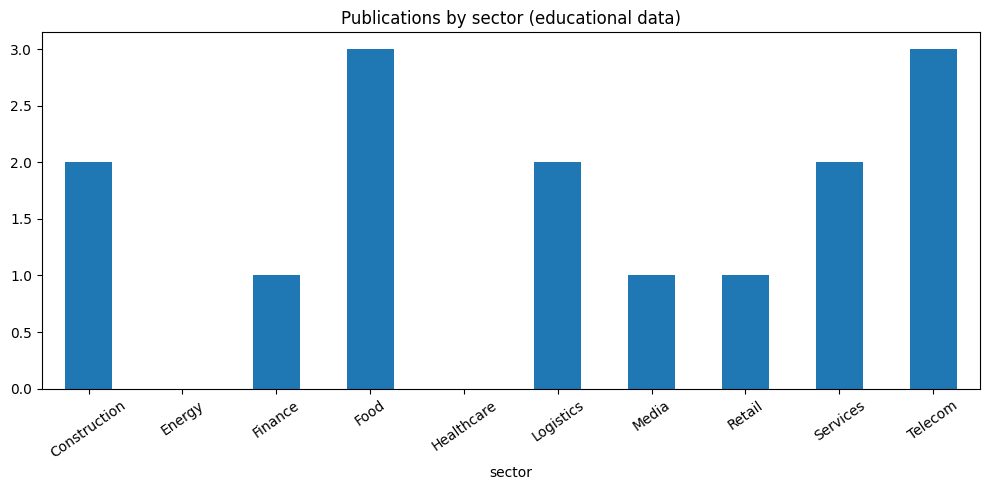

In [6]:
# LEFT JOIN с витриной лабораторной II и график публикаций по секторам
mart = pd.read_csv(ROOT / 'data_mart.csv')
web = pd.read_csv(ROOT / 'data/processed/catalog_clean.csv')
mart['org_id'] = mart['org_id'].astype('int64')
web['org_id'] = web['org_id'].astype('int64')
enriched = mart.merge(web, on='org_id', how='left', indicator=True, validate='one_to_one', suffixes=('', '_web'))
enriched.to_csv(ROOT / 'data/processed/data_mart_web.csv', index=False)
print(enriched['_merge'].value_counts())
grouped = enriched.assign(
    sector=enriched['sector_web'].fillna('Unknown / missing profile'),
    reports_count=pd.to_numeric(enriched['reports_count'], errors='coerce').fillna(0),
).groupby('sector', as_index=False)['reports_count'].sum()
import matplotlib.pyplot as plt
grouped.plot.bar(x='sector', y='reports_count', legend=False, figsize=(10, 5), rot=35, title='Publications by sector (educational data)')
plt.tight_layout()
plt.savefig(ROOT / 'results/reports_by_sector.png', dpi=150)
grouped

In [7]:
if server.poll() is None:
    server.terminate()
    server.wait(timeout=5)
print('Local server stopped')

Local server stopped
